# Task 1.3(b, c): preparing one definite codeword, |+α⟩

**In plain words.** Starting from an empty memory always gives the even cat, a superposition of both valleys. That is not a bug: the model looks the same if you swap $a\to-a$ (it has a mirror symmetry), and the empty memory is mirror-symmetric too, so nothing can favour one valley. The buffer drive only touches the buffer, so changing it can't help. **To land in one valley we must give the memory itself a push** in the direction of $+\alpha$.

We test two pushes, in the full two-mode model at the converged size 32×12:

- **A. Push first, then stabilize.** A short pulse on the memory makes a coherent state $|\beta\rangle$ (pointing right), then the pump turns on and the dissipation pulls it into the nearest valley. This is the order used in the Réglade et al. experiment.
- **B. Push while inflating.** Drive the memory with $i\varepsilon(a^\dagger-a)$ for the first 100 ns, starting from empty.
- **Control.** The other drive direction, $\varepsilon(a+a^\dagger)$, pushes along the *imaginary* axis, at right angles to both valleys, so by mirror symmetry it should *not* pick one. (Once the cat exists, this same drive is the Zeno Z gate.)

We score each with the fidelity with $|+\alpha\rangle$ and with $\mathrm{Re}\langle a\rangle/\alpha$ (1 = right valley, 0 = no preference, −1 = wrong valley).

The run takes ~10 min on 4 CPU cores, so the notebook **loads** the saved results by default. Set `RERUN = True` to recompute.

In [1]:
import sys, json, io
from pathlib import Path
from contextlib import redirect_stdout
from IPython.display import Image, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src/config.py').is_file() and (p / 'docs/challenge_prompt_v4.md').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
show = lambda name, w=1000: display(Image(filename=str(ROOT / 'figures' / f'{name}.png'), width=w))
load = lambda name: json.loads((ROOT / 'results' / f'{name}.json').read_text())


In [2]:
RERUN = False
if RERUN:
    from src import config as C
    from tasks import task_1_3b
    with redirect_stdout(io.StringIO()):
        task_1_3b.main(C.NA, C.NB)
r = load('task_1_3b')

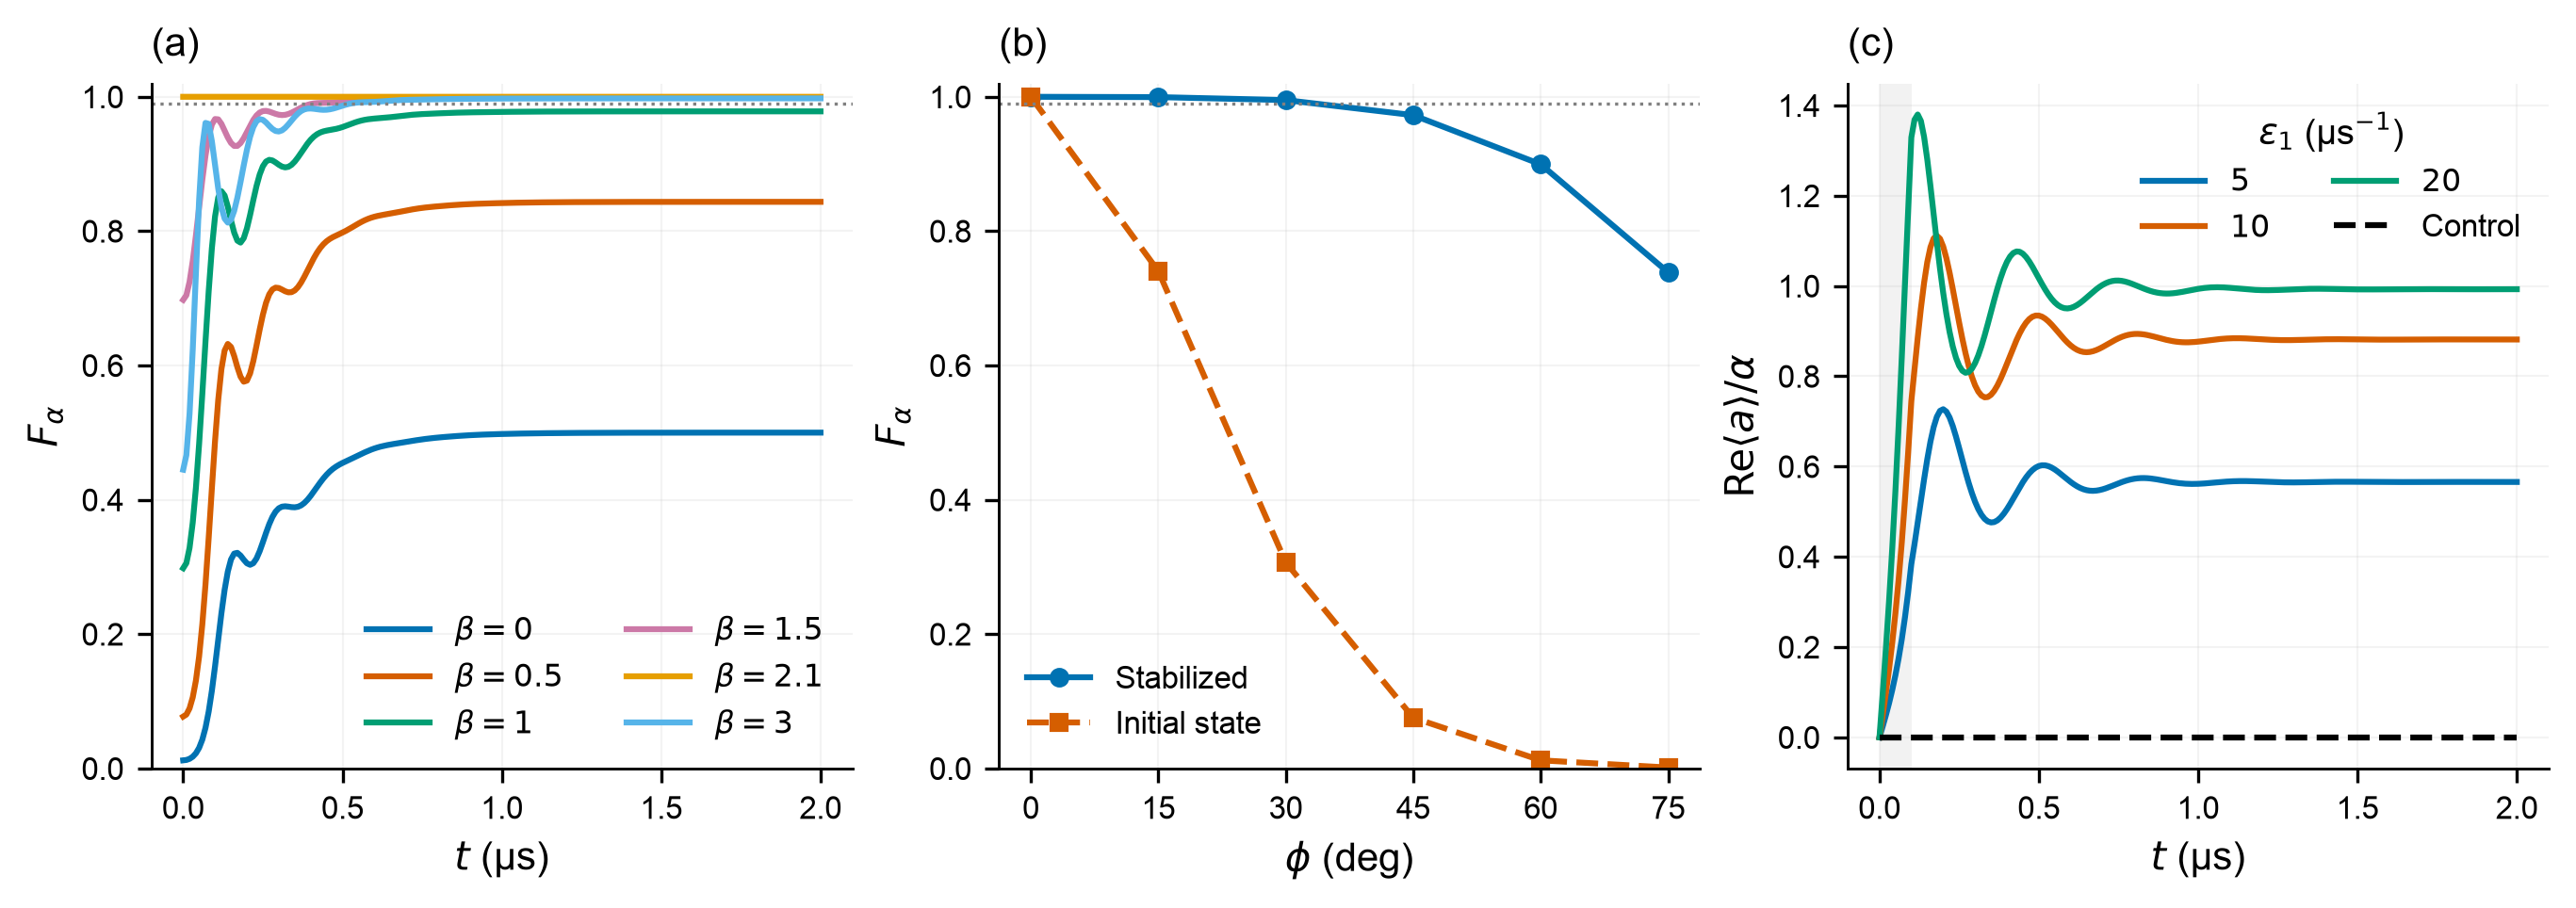

In [3]:
show('task_1_3b_logical_prep', 1150)

**Preparation of a selected coherent state.** Fidelity is $F_\alpha=\langle\alpha|\rho_a|\alpha\rangle$. (a) Evolution from $|\beta\rangle_a|0\rangle_b$ for real $\beta$. (b) Fidelity at $t=2$ µs after stabilization, compared with the initial overlap $|\langle\alpha|\beta\rangle|^2$, for $\beta=\alpha e^{i\phi}$. Dotted guides mark $F_\alpha=0.99$. (c) Normalized memory amplitude with a drive $i\varepsilon_1(a^\dagger-a)$ applied over the shaded interval, $0$–$0.1$ µs. The control uses $10(a+a^\dagger)$ in the same interval. Drive amplitudes are in µs⁻¹. All simulations use $(N_a,N_b)=(32,12)$ and $\alpha=2.1$.

## 1.3(c): what does it cost?

See `docs/TECHNICAL.md` Section 4b for the numbers. In short:

- **Hardware.** One extra control: a resonant drive on the memory. Alice & Bob already need one for the Zeno Z gate, so it is reused, not added.
- **Calibration.** The pulse's phase must be referenced to the pump, because the pump sets where the valleys sit ($\alpha^2 = \varepsilon_d/g_2$ fixes $\alpha$ only up to a sign). The stabilization forgives a sloppy pulse: amplitude errors of tens of percent and phase errors of up to ~30° still give $F \ge 0.99$, whereas the pulse alone would need to be almost perfect.
- **Interaction with the stabilization.** A drive applied *while* pumping competes with the dissipation: the wrong quadrature is a Z rotation, the right one shifts the valley. So the clean recipe is push first, then pump (method A). A push during inflation (B) also enlarges the overshoot, which needs a bigger simulation and, in hardware, more photons in the memory.
- **Time.** It reaches $F\ge0.99$ in a few hundred ns, comparable to the inflation itself, during which single-photon loss is still acting.

## Numerical summaries

In [4]:
import pandas as pd
cols = ['label', 'F_plus_alpha_2us', 're_a_over_alpha_2us', 't_F_099_us', 'bare_overlap', 'peak_na', 'max_top2_a', 'max_top_b']
for k in ('A1_amplitude', 'A2_phase', 'B_drive'):
    display(pd.DataFrame(r[k]).reindex(columns=cols).round(4))
r['control_wrong_quadrature']

,label,F_plus_alpha_2us,re_a_over_alpha_2us,t_F_099_us,bare_overlap,peak_na,max_top2_a,max_top_b
0,beta=0.0,0.5000,0.0000,inf,0.0122,6.8944,0.0,0.0002
1,beta=0.5,0.8436,0.6867,inf,0.0773,6.5598,0.0,0.0001
2,beta=1.0,0.9783,0.9559,inf,0.2982,6.2261,0.0,0.0000
3,beta=1.5,0.9988,0.9968,0.41,0.6977,5.5265,0.0,0.0000
4,beta=2.1,1.0000,0.9992,0.00,1.0000,4.4100,0.0,0.0000
5,beta=3.0,0.9977,0.9946,0.53,0.4449,9.0000,0.0,0.0000


,label,F_plus_alpha_2us,re_a_over_alpha_2us,t_F_099_us,bare_overlap,peak_na,max_top2_a,max_top_b
0,phase=0deg,1.0000,0.9992,0.00,1.0000,4.4100,0.0,0.0000
1,phase=15deg,0.9995,0.9983,0.37,0.7404,4.7389,0.0,0.0000
2,phase=30deg,0.9951,0.9894,0.67,0.3068,5.6016,0.0,0.0000
3,phase=45deg,0.9727,0.9446,inf,0.0755,6.5725,0.0,0.0000
4,phase=60deg,0.8994,0.7983,inf,0.0122,7.3075,0.0,0.0002
5,phase=75deg,0.7386,0.4768,inf,0.0014,7.9285,0.0,0.0005


,label,F_plus_alpha_2us,re_a_over_alpha_2us,t_F_099_us,bare_overlap,peak_na,max_top2_a,max_top_b
0,eps1=5.0,0.7832,0.5658,inf,NaN,6.6566,0.0,0.0001
1,eps1=10.0,0.9411,0.8815,inf,NaN,6.5856,0.0,0.0000
2,eps1=20.0,0.9968,0.9929,0.67,NaN,8.5135,0.0,0.0000


{'label': 'eps*(a+a^dag), eps=10',
 'F_plus_alpha_2us': 0.49999368271180133,
 're_a_over_alpha_2us': 0.0,
 't_F_099_us': inf,
 'peak_na': 7.207165433681015,
 'max_top2_a': 1.7328312405091482e-05,
 'max_top_b': 0.00022187639379422767}